# Denetimde Veri Analizi — İleri Konular

## Dr. Suat ATAN

**İç Denetim Koordinatörlüğü — Uygulamalı Notebook 2**

Bu notebook, temel Python–Pandas–EDA notebook'unun devamıdır. Amaç daha fazla Python komutu ezberlemek değil; **denetim sorusuna uygun analitik yöntemi seçmeyi** öğrenmektir.

### Bu notebook'ta ne yapacağız?

1. Doğru örnekleme mantığını konuşacağız.
2. Basit rastgele, tabakalı ve ağırlıklı rastgele örnekleme yapacağız.
3. İki değişken birlikte değerlendirildiğinde görülen aykırı gözlemleri yakalayacağız.
4. Zaman serisinde veri kesintisi ve sıra dışı düşüşleri bulacağız.
5. Hareketli (animated) grafik oluşturacağız.
6. Korelasyonu inceleyeceğiz.
7. Korelasyon ile nedensellik arasındaki farkı göreceğiz.
8. Zaman serilerinde **Granger nedensellik testi** uygulayacağız.

> **Ana fikir:** Analitik teknik tek başına denetim bulgusu değildir. Teknik, **incelemeye değer kayıtları önceliklendiren bir araçtır**.

## 0. Eğitim akışı ve yaklaşık süre

Bu notebook yaklaşık **90–120 dakikalık** bir ileri seans için tasarlanmıştır.

- Örnekleme: 20–25 dk
- İki değişkenli aykırı değer: 15–20 dk
- Zaman serisi / kesinti: 15–20 dk
- Hareketli grafik: 10 dk
- Korelasyon: 10–15 dk
- Granger testi ve nedensellik tartışması: 15–20 dk

Her bölümde önce **denetim sorusunu**, sonra yöntemi, sonra Python kodunu göreceğiz.

## 1. Kurulum ve tekrar üretilebilirlik

Denetim analizlerinde aynı kodun tekrar çalıştırıldığında aynı sonucu üretmesi önemlidir.

Bu nedenle rastgele sayı kullanılan yerlerde `random_state` veya `seed` kullanacağız.

> **Denetim izi açısından önemli:**  
> “Rastgele 30 kayıt seçtim” demek yerine, hangi yöntemle ve hangi seed değeriyle seçildiğini kaydetmek örneklemenin yeniden üretilebilmesini sağlar.

In [1]:
import importlib.util
import subprocess
import sys

# Colab'da genellikle hazır gelir. Eksikse kurulur.
for package in ["plotly", "statsmodels"]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

from scipy.stats import chi2
from statsmodels.tsa.stattools import grangercausalitytests

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Kurulum tamamlandı. random_state =", RANDOM_STATE)

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-ru7cgi6y because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Kurulum tamamlandı. random_state = 42


## 2. Eğitim için örnek veri seti oluşturalım

Gerçek denetim verilerinde genellikle şu alanların benzerlerini görürüz:

- işlem tarihi,
- birim,
- tedarikçi,
- işlem tutarı,
- onay süresi,
- risk skoru.

Aşağıdaki veri **eğitim amaçlı sentetik veridir**. İçine özellikle bazı sıra dışı kayıtlar ve zaman serisi kesintileri yerleştirilmiştir.

In [2]:
n = 1200

dates = pd.date_range("2026-01-01", "2026-06-30", freq="D")
units = np.array(["Satın Alma", "İnsan Kaynakları", "BT", "Mali İşler"])
suppliers = np.array([f"Tedarikçi {i:02d}" for i in range(1, 41)])

transactions = pd.DataFrame({
    "islem_id": np.arange(1, n + 1),
    "tarih": rng.choice(dates, size=n),
    "birim": rng.choice(units, size=n, p=[0.38, 0.18, 0.22, 0.22]),
    "tedarikci": rng.choice(suppliers, size=n),
})

# Sağa çarpık parasal dağılım
transactions["tutar"] = rng.lognormal(mean=9.3, sigma=0.9, size=n)

# Tutar arttıkça ortalama onay süresi biraz artsın; ama gürültü de olsun
transactions["onay_suresi_gun"] = (
    1.5
    + np.log1p(transactions["tutar"]) * 0.42
    + rng.normal(0, 1.4, size=n)
).clip(0.2)

# Basit bir eğitim risk skoru
transactions["risk_skoru"] = (
    20
    + 12 * (transactions["tutar"] > transactions["tutar"].quantile(0.90)).astype(int)
    + 8 * (transactions["onay_suresi_gun"] > transactions["onay_suresi_gun"].quantile(0.90)).astype(int)
    + rng.normal(0, 7, size=n)
).clip(0, 100)

# İki değişken birlikte düşünülünce sıra dışı olacak birkaç kayıt
special_idx = rng.choice(transactions.index, size=8, replace=False)
transactions.loc[special_idx[:4], ["tutar", "onay_suresi_gun"]] = [
    [250_000, 1.0],
    [320_000, 0.8],
    [280_000, 1.2],
    [350_000, 0.9],
]
transactions.loc[special_idx[4:], ["tutar", "onay_suresi_gun"]] = [
    [3_000, 15.0],
    [4_000, 17.0],
    [2_500, 14.0],
    [3_500, 16.0],
]

transactions = transactions.sort_values("tarih").reset_index(drop=True)

transactions.head()

,islem_id,tarih,birim,tedarikci,tutar,onay_suresi_gun,risk_skoru
0,901,2026-01-01,BT,Tedarikçi 28,"30,774.42",4.76,22.75
1,381,2026-01-01,Mali İşler,Tedarikçi 19,"3,817.50",3.49,13.44
2,845,2026-01-01,Satın Alma,Tedarikçi 30,"9,855.42",3.74,23.23
3,846,2026-01-01,BT,Tedarikçi 17,"28,358.94",6.16,22.24
4,773,2026-01-01,İnsan Kaynakları,Tedarikçi 10,"20,310.38",3.57,14.36


In [3]:
print("Satır sayısı:", len(transactions))
print("\nBirim dağılımı:")
display(transactions["birim"].value_counts())

print("\nTemel özet:")
display(transactions[["tutar", "onay_suresi_gun", "risk_skoru"]].describe())

Satır sayısı: 1200

Birim dağılımı:


birim
Satın Alma          450
Mali İşler          288
BT                  240
İnsan Kaynakları    222
Name: count, dtype: int64


Temel özet:


,tutar,onay_suresi_gun,risk_skoru
count,"1,200.00","1,200.00","1,200.00"
mean,"17,574.88",5.42,22.21
std,"24,400.53",1.58,8.26
min,832.67,0.76,0.00
25%,"6,031.63",4.41,16.64
50%,"11,054.61",5.41,22.02
75%,"21,168.17",6.33,27.42
max,"350,000.00",17.00,57.74


# 3. Örnekleme: “Kaç kayıt seçelim?” sorusundan önce “Nasıl seçelim?”

Denetimde örnekleme yalnızca veri küçültme değildir. Yanlış örnekleme, doğru kodla bile yanlış sonuca götürebilir.

### Üç temel soru

**1. Evren nedir?**  
Hangi işlemler bu denetim sorusunun kapsamındadır?

**2. Her kaydın seçilme şansı aynı mı olmalı?**  
Her zaman değil. Bazen büyük tutarlar veya yüksek riskli işlemler özellikle daha fazla temsil edilmek istenir.

**3. Sonuçtan ne bekliyoruz?**
- Evren hakkında tarafsız tahmin mi?
- Yüksek riskli işlemleri bulmak mı?
- Her birimin temsil edilmesini sağlamak mı?

Bu üç amaç farklı örnekleme yöntemleri gerektirebilir.

## 3.1 Basit rastgele örnekleme

Her kaydın seçilme olasılığı aynıdır.

Avantajı: Basit ve açıklanabilir.  
Riski: Küçük gruplar örnekte hiç yer almayabilir.

In [4]:
simple_sample = transactions.sample(n=40, random_state=RANDOM_STATE)

display(simple_sample.head())

print("Örnek birim dağılımı:")
display(simple_sample["birim"].value_counts())

,islem_id,tarih,birim,tedarikci,tutar,onay_suresi_gun,risk_skoru
1178,594,2026-06-27,Mali İşler,Tedarikçi 02,"8,399.58",4.76,5.87
865,1137,2026-05-12,Mali İşler,Tedarikçi 03,"21,154.71",3.89,22.58
101,951,2026-01-17,Satın Alma,Tedarikçi 02,"17,947.90",3.53,18.05
439,614,2026-03-11,İnsan Kaynakları,Tedarikçi 29,"5,638.39",3.24,17.73
58,699,2026-01-10,BT,Tedarikçi 02,"24,345.08",4.86,29.07


Örnek birim dağılımı:


birim
Mali İşler          12
Satın Alma          11
BT                  10
İnsan Kaynakları     7
Name: count, dtype: int64

## 3.2 Tabakalı örnekleme

Denetçi bazen her birimin mutlaka örnekte bulunmasını ister. Bu durumda evreni önce gruplara (**tabakalara**) ayırabiliriz.

Aşağıdaki örnekte her birimden yaklaşık aynı sayıda kayıt alıyoruz.

> Bu yöntem özellikle küçük birimin, büyük birimin hacmi içinde kaybolmasını önler.

In [5]:
stratified_sample = (
    transactions
    .groupby("birim", group_keys=False)
    .sample(n=10, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

display(stratified_sample[["islem_id", "birim", "tutar", "risk_skoru"]].head(12))

print("Tabakalı örnekte birim dağılımı:")
display(stratified_sample["birim"].value_counts())

,islem_id,birim,tutar,risk_skoru
0,581,BT,"5,588.66",22.71
1,821,BT,"28,503.68",26.05
2,1094,BT,"7,815.79",23.36
3,219,BT,"2,145.97",17.67
4,777,BT,"10,525.81",23.19
5,1041,BT,"4,161.65",27.89
6,959,BT,"4,411.33",21.17
7,53,BT,"14,087.68",19.90
8,117,BT,"7,358.00",13.70
9,665,BT,"26,596.17",29.53


Tabakalı örnekte birim dağılımı:


birim
BT                  10
Mali İşler          10
Satın Alma          10
İnsan Kaynakları    10
Name: count, dtype: int64

## 3.3 Ağırlıklı rastgele örnekleme — PPS mantığı

Bazen büyük tutarlı işlemlerin seçilme olasılığını artırmak isteriz.

Bu yaklaşım **Probability Proportional to Size (PPS)** mantığına benzer.

Burada ağırlığı `tutar` olarak kullanacağız. Yüksek tutarlı kayıtların seçilme şansı daha yüksek olacaktır.

> **Kritik uyarı:**  
> Ağırlıklı seçim, yüksek riskli/büyük kayıtları bulmak için çok faydalıdır; ancak bu örnek üzerinden doğrudan “evrenin yüzde kaçı hatalı?” gibi tarafsız tahmin yapmak doğru olmayabilir. Çünkü kayıtların seçilme olasılıkları eşit değildir.

In [6]:
weighted_sample = transactions.sample(
    n=40,
    weights="tutar",
    random_state=RANDOM_STATE
)

comparison = pd.DataFrame({
    "Evren ortalama tutar": [transactions["tutar"].mean()],
    "Basit rastgele örnek": [simple_sample["tutar"].mean()],
    "Ağırlıklı örnek": [weighted_sample["tutar"].mean()],
})

display(comparison)

print("\nAğırlıklı örnekten ilk kayıtlar:")
display(weighted_sample[["islem_id", "birim", "tutar", "risk_skoru"]]
        .sort_values("tutar", ascending=False)
        .head(10))

,Evren ortalama tutar,Basit rastgele örnek,Ağırlıklı örnek
0,"17,574.88","19,762.26","58,903.60"



Ağırlıklı örnekten ilk kayıtlar:


,islem_id,birim,tutar,risk_skoru
944,725,Satın Alma,"350,000.00",21.88
615,449,Mali İşler,"280,000.00",15.80
983,514,Mali İşler,"171,712.72",35.72
528,792,Mali İşler,"167,474.47",42.60
543,1075,Mali İşler,"137,723.41",26.77
23,300,İnsan Kaynakları,"94,222.01",39.14
225,661,Satın Alma,"91,472.60",37.44
691,242,Mali İşler,"76,327.85",39.54
68,619,BT,"68,067.84",32.04
365,749,İnsan Kaynakları,"66,964.76",45.06


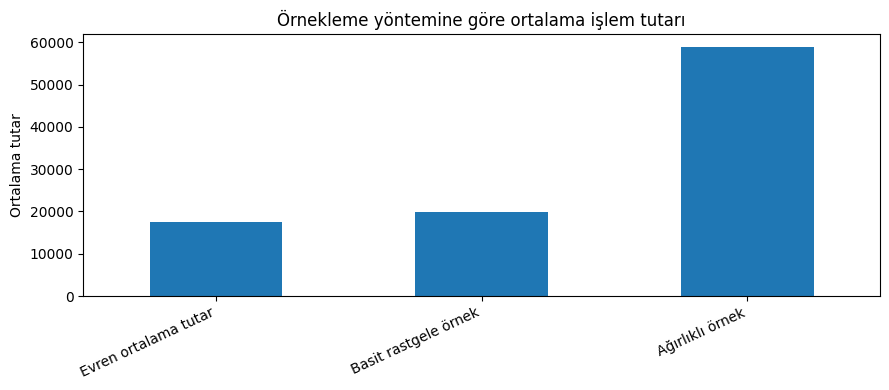

In [7]:
comparison.T.plot(kind="bar", legend=False, figsize=(9, 4))
plt.title("Örnekleme yöntemine göre ortalama işlem tutarı")
plt.ylabel("Ortalama tutar")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Denetim yorumu

Ağırlıklı örneğin ortalama tutarının evrenden daha yüksek olması **hata değildir**; yöntemin doğal sonucudur.

Bu nedenle denetim çalışma kağıdında yalnızca örnek büyüklüğünü değil, **örnekleme yöntemini ve seçilme mantığını** da yazmak gerekir.

# 4. İki değişkenli aykırı değer: Tek tek normal, birlikte sıra dışı

Tek değişkenli outlier analizinde örneğin yalnızca `tutar` sütununa bakarız.

Fakat bazı kayıtlar:
- tutar açısından tek başına çok sıra dışı olmayabilir,
- onay süresi açısından tek başına çok sıra dışı olmayabilir,
- **ama bu iki değişkenin kombinasyonu sıra dışı olabilir.**

Örnek:
- Çok büyük bir satın alma işleminin alışılmadık derecede hızlı onaylanması,
- Çok küçük bir işlemin olağanüstü uzun sürede onaylanması.

Bunu görmek için iki boyutlu uzaklık ölçüsü olan **Mahalanobis uzaklığını** kullanacağız.

In [8]:
X = transactions[["tutar", "onay_suresi_gun"]].copy()

# Tutar çok sağa çarpık olduğu için log dönüşümü yapıyoruz.
X["log_tutar"] = np.log1p(X["tutar"])
X2 = X[["log_tutar", "onay_suresi_gun"]]

mean_vector = X2.mean().values
cov_matrix = np.cov(X2.values, rowvar=False)
inv_cov_matrix = np.linalg.inv(cov_matrix)

centered = X2.values - mean_vector
mahalanobis_sq = np.einsum(
    "ij,jk,ik->i",
    centered,
    inv_cov_matrix,
    centered
)

transactions["mahalanobis_d2"] = mahalanobis_sq

# 2 değişken için %99 güven düzeyinde eşik
threshold = chi2.ppf(0.99, df=2)
transactions["iki_degiskenli_outlier"] = transactions["mahalanobis_d2"] > threshold

print("Mahalanobis d² eşiği:", round(threshold, 2))
print("Yakalanan kayıt sayısı:", transactions["iki_degiskenli_outlier"].sum())

display(
    transactions.loc[
        transactions["iki_degiskenli_outlier"],
        ["islem_id", "tutar", "onay_suresi_gun", "mahalanobis_d2"]
    ].sort_values("mahalanobis_d2", ascending=False).head(15)
)

Mahalanobis d² eşiği: 9.21
Yakalanan kayıt sayısı: 14


,islem_id,tutar,onay_suresi_gun,mahalanobis_d2
673,79,"4,000.00",17.00,59.93
593,159,"3,500.00",16.00,51.20
1151,515,"3,000.00",15.00,43.40
632,1164,"2,500.00",14.00,36.57
944,725,"350,000.00",0.90,26.95
514,869,"320,000.00",0.80,26.56
615,449,"280,000.00",1.20,23.54
305,211,"250,000.00",1.00,23.40
1078,592,"34,154.31",10.72,11.70
543,1075,"137,723.41",9.05,10.94


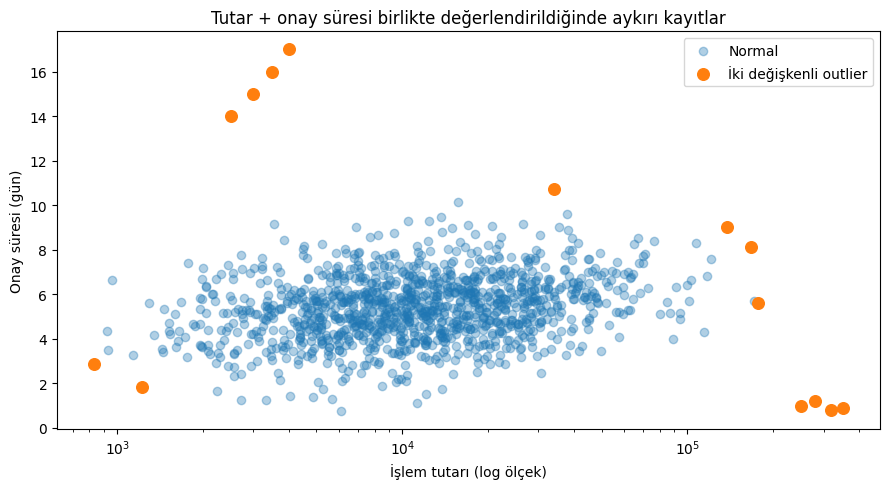

In [9]:
normal = transactions[~transactions["iki_degiskenli_outlier"]]
outliers = transactions[transactions["iki_degiskenli_outlier"]]

plt.figure(figsize=(9, 5))
plt.scatter(
    normal["tutar"],
    normal["onay_suresi_gun"],
    alpha=0.35,
    label="Normal"
)
plt.scatter(
    outliers["tutar"],
    outliers["onay_suresi_gun"],
    s=70,
    label="İki değişkenli outlier"
)
plt.xscale("log")
plt.xlabel("İşlem tutarı (log ölçek)")
plt.ylabel("Onay süresi (gün)")
plt.title("Tutar + onay süresi birlikte değerlendirildiğinde aykırı kayıtlar")
plt.legend()
plt.tight_layout()
plt.show()

### Neden bu yöntem denetimde değerlidir?

Tek bir eşik kuralı genellikle şu tür ilişkileri kaçırır:

> “Bu tutardaki bir işlem için bu onay süresi olağan mı?”

Bu soru artık tek sütunlu değil, **ilişkisel bir anomali sorusudur**.

Gerçek projelerde daha fazla değişken olduğunda Isolation Forest, Local Outlier Factor veya robust covariance gibi yöntemlere geçilebilir. Fakat mantık aynıdır: **kaydın bağlam içindeki olağanlığını sorgulamak**.

# 5. Zaman serisinde kesinti yakalama

Denetimde bazen tek bir sıra dışı kayıt değil, **veri akışındaki kopma** önemlidir.

Örnekler:
- Bir sistemin birkaç gün veri üretmemesi,
- Tahakkukların aniden durması,
- Ödeme kayıtlarının belirli günlerde kaybolması,
- Bir sensör veya uygulama logunun kesilmesi.

Önce günlük işlem sayısını çıkaralım. Ardından eğitim amacıyla bazı günleri veri setinden tamamen çıkaracağız.

In [10]:
daily = (
    transactions
    .groupby("tarih")
    .size()
    .rename("islem_sayisi")
    .sort_index()
)

full_dates = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily_full = daily.reindex(full_dates)

# Eğitim için planlı bir "veri kesintisi" daha oluşturalım:
gap_days = pd.date_range("2026-04-10", "2026-04-15", freq="D")
daily_with_gap = daily_full.copy()
daily_with_gap.loc[gap_days] = np.nan

missing_days = daily_with_gap[daily_with_gap.isna()].index

print("Eksik gün sayısı:", len(missing_days))
print("İlk eksik tarihler:", list(missing_days[:12]))

Eksik gün sayısı: 6
İlk eksik tarihler: [Timestamp('2026-04-10 00:00:00'), Timestamp('2026-04-11 00:00:00'), Timestamp('2026-04-12 00:00:00'), Timestamp('2026-04-13 00:00:00'), Timestamp('2026-04-14 00:00:00'), Timestamp('2026-04-15 00:00:00')]


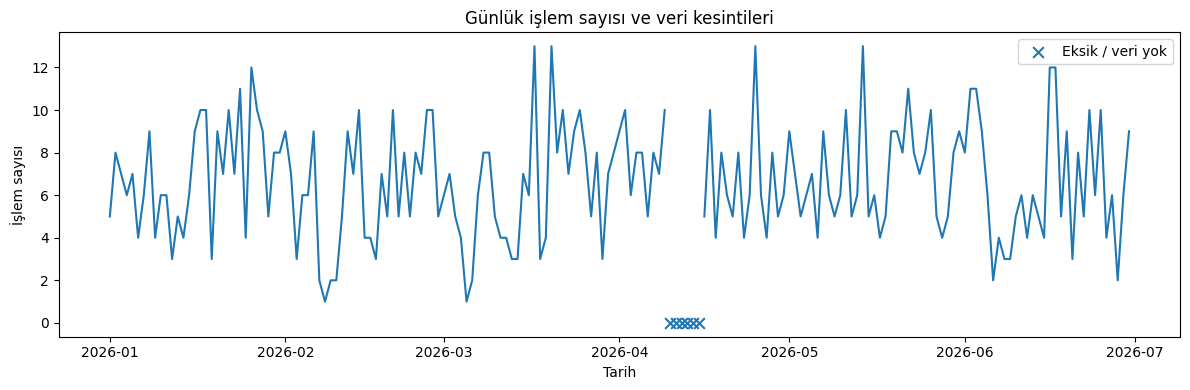

In [11]:
plt.figure(figsize=(12, 4))
plt.plot(daily_with_gap.index, daily_with_gap.values)
plt.scatter(
    missing_days,
    np.zeros(len(missing_days)),
    marker="x",
    s=60,
    label="Eksik / veri yok"
)
plt.title("Günlük işlem sayısı ve veri kesintileri")
plt.xlabel("Tarih")
plt.ylabel("İşlem sayısı")
plt.legend()
plt.tight_layout()
plt.show()

## 5.1 Eksik tarih ile “sıfır işlem” aynı şey değildir

Bu ayrım denetimde çok önemlidir:

- `0` = sistem kayıt üretmiş ve o gün işlem yok.
- `NaN / eksik tarih` = o güne ilişkin verinin gelip gelmediğini bilmiyoruz.

Bir veri hattındaki kesintiyi yanlışlıkla `0` ile doldurmak, veri kalitesi problemini iş davranışı gibi gösterebilir.

## 5.2 Ani düşüşleri hareketli baz çizgi ile yakalamak

Şimdi yalnızca eksik günlere değil, olağandışı düşük aktiviteye de bakalım.

Basit bir yaklaşım:
- Son 14 günün medyanını “normal seviye” kabul et,
- Günlük değer bu seviyenin %30'undan küçükse inceleme adayı yap.

In [12]:
ts = daily_full.fillna(0).to_frame()
ts["rolling_median_14"] = ts["islem_sayisi"].rolling(14, min_periods=7).median()
ts["ani_dusus"] = (
    ts["rolling_median_14"].notna()
    & (ts["islem_sayisi"] < ts["rolling_median_14"] * 0.30)
)

display(ts[ts["ani_dusus"]].head(15))

,islem_sayisi,rolling_median_14,ani_dusus
2026-02-07,2,7.50,True
2026-02-08,1,7.50,True
2026-03-05,1,6.50,True
2026-04-12,2,8.00,True
2026-06-06,2,8.00,True


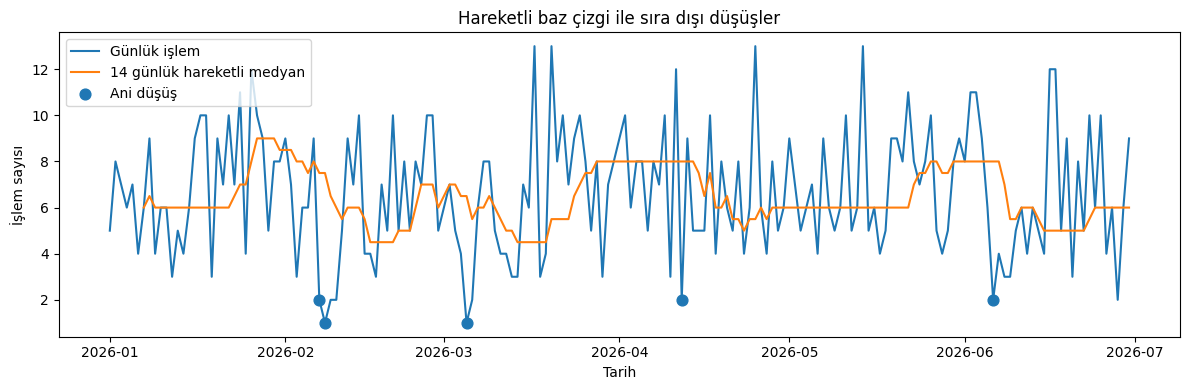

In [13]:
plt.figure(figsize=(12, 4))
plt.plot(ts.index, ts["islem_sayisi"], label="Günlük işlem")
plt.plot(ts.index, ts["rolling_median_14"], label="14 günlük hareketli medyan")

alerts = ts[ts["ani_dusus"]]
plt.scatter(
    alerts.index,
    alerts["islem_sayisi"],
    s=60,
    label="Ani düşüş"
)

plt.title("Hareketli baz çizgi ile sıra dışı düşüşler")
plt.xlabel("Tarih")
plt.ylabel("İşlem sayısı")
plt.legend()
plt.tight_layout()
plt.show()

# 6. Hareketli grafik: Verinin zaman içindeki davranışını izlemek

Statik grafik tek bir anı gösterir. Hareketli grafik ise dağılımın zamanla nasıl değiştiğini gösterebilir.

Denetimde örneğin:
- tedarikçi risklerinin aylara göre değişimi,
- birimlerin zaman içinde işlem hacmi,
- yüksek tutarlı işlemlerin belirli dönemlerde yoğunlaşması

gibi örüntüleri anlatmak için kullanılabilir.

Aşağıda her ay için birimlerin ortalama tutar ve risk skorunu hareketli grafikle gösteriyoruz.

In [14]:
animated = transactions.copy()
animated["ay"] = animated["tarih"].dt.to_period("M").astype(str)

monthly_unit = (
    animated
    .groupby(["ay", "birim"], as_index=False)
    .agg(
        ortalama_tutar=("tutar", "mean"),
        ortalama_risk=("risk_skoru", "mean"),
        islem_sayisi=("islem_id", "count")
    )
)

fig = px.scatter(
    monthly_unit,
    x="ortalama_tutar",
    y="ortalama_risk",
    size="islem_sayisi",
    color="birim",
    animation_frame="ay",
    hover_name="birim",
    log_x=True,
    range_y=[
        max(0, monthly_unit["ortalama_risk"].min() - 5),
        min(100, monthly_unit["ortalama_risk"].max() + 5)
    ],
    title="Birimlerin aylara göre tutar ve risk profili"
)
fig.show()

### Sunumda sorulabilecek soru

Grafiği oynatırken şunu sorun:

> “Bir birimin risk profilinin belirli bir ayda aniden yer değiştirmesi sizce ne anlatabilir?”

Buradaki amaç hareketli grafiğin kendisi değil; **zaman boyutunu analize eklemek**.

# 7. Korelasyon: İki değişken birlikte hareket ediyor mu?

Korelasyon iki değişken arasındaki **doğrusal ilişkinin yönünü ve gücünü** özetler.

- +1'e yakın: birlikte artma eğilimi
- -1'e yakın: biri artarken diğerinin azalma eğilimi
- 0'a yakın: güçlü doğrusal ilişki yok

Fakat:

> **Korelasyon nedensellik değildir.**

İki değişkenin birlikte hareket etmesi:
- A'nın B'ye neden olduğunu,
- B'nin A'ya neden olduğunu,
- veya üçüncü bir değişkenin ikisini de etkilemediğini

tek başına göstermez.

,tutar,onay_suresi_gun,risk_skoru
tutar,1.00,0.04,0.25
onay_suresi_gun,0.04,1.00,0.22
risk_skoru,0.25,0.22,1.00


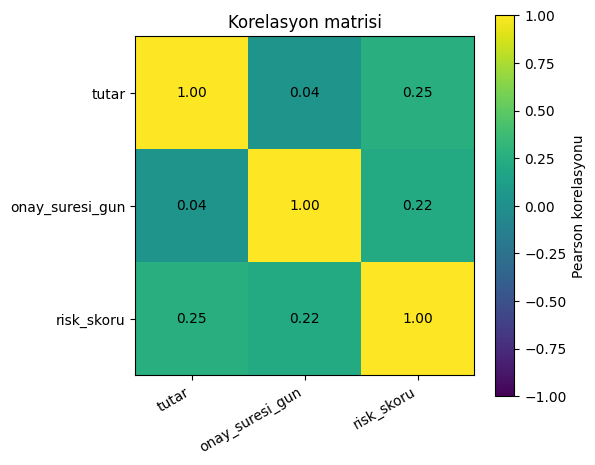

In [15]:
corr_cols = ["tutar", "onay_suresi_gun", "risk_skoru"]
corr = transactions[corr_cols].corr()

display(corr)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.values, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=30, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

ax.set_title("Korelasyon matrisi")
fig.colorbar(im, ax=ax, label="Pearson korelasyonu")
plt.tight_layout()
plt.show()

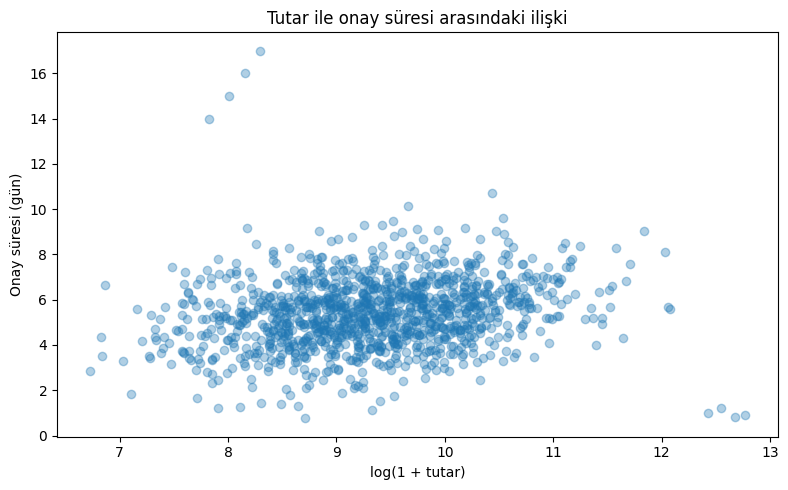

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(
    np.log1p(transactions["tutar"]),
    transactions["onay_suresi_gun"],
    alpha=0.35
)
plt.xlabel("log(1 + tutar)")
plt.ylabel("Onay süresi (gün)")
plt.title("Tutar ile onay süresi arasındaki ilişki")
plt.tight_layout()
plt.show()

# 8. Korelasyondan nedenselliğe geçerken dikkat

Bir denetçi için şu iki cümle aynı değildir:

**Cümle A:**  
“Yoğunluk arttığında onay süresi de artıyor.”

**Cümle B:**  
“Yoğunluğun artması onay süresinin artmasına neden oluyor.”

İkinci cümle çok daha güçlü bir iddiadır.

Gerçek nedensel çıkarım için deney tasarımı, doğal deney, kontrol grubu, Difference-in-Differences, instrumental variables gibi yöntemler gerekebilir.

Zaman serilerinde kullanılan **Granger nedensellik testi** ise daha sınırlı bir soru sorar:

> “X'in geçmiş değerleri, Y'nin gelecekteki değerlerini tahmin etmeye ek bilgi sağlıyor mu?”

Bu nedenle Granger sonucunu **gerçek dünyada nedenselliğin kesin kanıtı** olarak yorumlamamalıyız.

## 8.1 Granger nedensellik için eğitim verisi

Aşağıdaki sentetik örnekte:
- günlük iş yükünü (`is_yuku`) oluşturacağız,
- bir gün önceki iş yükünün bugünkü ortalama onay süresini etkilediği bir yapı kuracağız.

Bu ilişkiyi bildiğimiz için testin neyi yakaladığını rahatça görebiliriz.

In [17]:
n_days = 180
granger_dates = pd.date_range("2026-01-01", periods=n_days, freq="D")

workload = 100 + rng.normal(0, 12, n_days)
approval_delay = np.zeros(n_days)

approval_delay[0] = 4.0
for t in range(1, n_days):
    approval_delay[t] = (
        2.0
        + 0.035 * workload[t - 1]
        + 0.35 * approval_delay[t - 1]
        + rng.normal(0, 0.7)
    )

causal_df = pd.DataFrame({
    "tarih": granger_dates,
    "is_yuku": workload,
    "onay_suresi": approval_delay
}).set_index("tarih")

causal_df.head()

,is_yuku,onay_suresi
tarih,,
2026-01-01,109.37,4.00
2026-01-02,82.62,5.77
2026-01-03,114.90,6.82
2026-01-04,95.09,9.42
2026-01-05,83.17,9.80


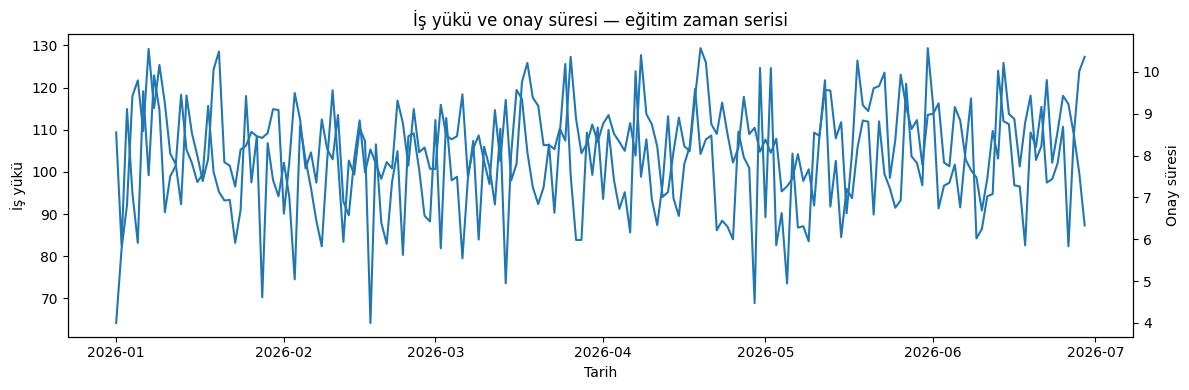

In [18]:
fig, ax1 = plt.subplots(figsize=(12, 4))

ax1.plot(causal_df.index, causal_df["is_yuku"], label="İş yükü")
ax1.set_ylabel("İş yükü")
ax1.set_xlabel("Tarih")

ax2 = ax1.twinx()
ax2.plot(causal_df.index, causal_df["onay_suresi"], label="Onay süresi")
ax2.set_ylabel("Onay süresi")

plt.title("İş yükü ve onay süresi — eğitim zaman serisi")
fig.tight_layout()
plt.show()

## 8.2 Granger testi

Test yönlüdür.

Önce şu soruyu soruyoruz:

> “Geçmiş iş yükü değerleri, onay süresini tahmin etmeyi iyileştiriyor mu?”

`p < 0.05` ise, seçilen gecikme (lag) için “iş yükü onay süresini Granger anlamında açıklamaya katkı sağlamıyor” şeklindeki sıfır hipotezini reddederiz.

In [19]:
# statsmodels fonksiyonu kolon sırasına duyarlıdır:
# [hedef, açıklayıcı] => açıklayıcı Granger anlamında hedefi öngörüyor mu?
test_data = causal_df[["onay_suresi", "is_yuku"]]

results = grangercausalitytests(test_data, maxlag=3, verbose=False)

granger_summary = []
for lag, result in results.items():
    p_value = result[0]["ssr_ftest"][1]
    granger_summary.append({
        "lag": lag,
        "p_degeri": p_value,
        "0.05_altinda_mi": p_value < 0.05
    })

granger_summary = pd.DataFrame(granger_summary)
display(granger_summary)

/opt/pyvenv/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning:

verbose is deprecated since functions should not print results



,lag,p_degeri,0.05_altinda_mi
0,1,0.00,True
1,2,0.00,True
2,3,0.00,True


### Ters yönü de test etmek gerekir

Şimdi tersini soralım:

> “Geçmiş onay süresi, iş yükünü öngörüyor mu?”

Bu iki yönün ayrı ayrı sınanması önemlidir.

In [20]:
reverse_data = causal_df[["is_yuku", "onay_suresi"]]
reverse_results = grangercausalitytests(reverse_data, maxlag=3, verbose=False)

reverse_summary = []
for lag, result in reverse_results.items():
    p_value = result[0]["ssr_ftest"][1]
    reverse_summary.append({
        "lag": lag,
        "p_degeri": p_value,
        "0.05_altinda_mi": p_value < 0.05
    })

reverse_summary = pd.DataFrame(reverse_summary)
display(reverse_summary)

/opt/pyvenv/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning:

verbose is deprecated since functions should not print results



,lag,p_degeri,0.05_altinda_mi
0,1,0.08,False
1,2,0.08,False
2,3,0.05,False


### Granger sonucunu nasıl söyleyelim?

**Doğruya yakın ifade:**

> “Geçmiş iş yükü değerleri, onay süresinin tahmininde ek bilgi sağlıyor.”

**Kaçınılması gereken ifade:**

> “İş yükünün onay süresine kesin olarak neden olduğunu kanıtladık.”

Çünkü gerçek veride:
- ortak nedenler,
- sezon etkileri,
- trend,
- veri kalitesi,
- yanlış lag seçimi,
- durağanlık problemleri

sonucu etkileyebilir.

# 9. Bir denetçi bu yöntemleri ne zaman kullanmalı?

| Denetim sorusu | Uygun başlangıç yöntemi |
|---|---|
| Evrenden tarafsız kayıt seçmek istiyorum | Basit rastgele örnekleme |
| Her birim mutlaka temsil edilsin | Tabakalı örnekleme |
| Büyük tutarlı işlemlere daha fazla odaklanmak istiyorum | Ağırlıklı/PPS örnekleme |
| İki özellik birlikte düşünüldüğünde tuhaf kayıtları arıyorum | Çok değişkenli outlier / Mahalanobis |
| Veri akışında kopukluk var mı? | Tarih reindex + gap analizi |
| Aktivitede sıra dışı düşüş oldu mu? | Rolling baseline / kontrol grafiği |
| Davranış zamanla nasıl değişiyor? | Zaman serisi / hareketli grafik |
| İki değişken birlikte hareket ediyor mu? | Korelasyon |
| Bir zaman serisinin geçmişi diğerini öngörüyor mu? | Granger testi |

# 10. Bonus fikirler — sonraki adımlar

Bu notebook'tan sonra denetim analitiğinde şu konulara geçilebilir:

### Kontrol grafikleri
Normal süreç davranışının dışına çıkan dönemleri belirlemek.

### Isolation Forest
Çok sayıda değişken kullanarak olağandışı işlemleri otomatik puanlamak.

### Network analysis
Tedarikçi–personel–adres–IBAN–telefon gibi ortak noktaları kullanarak ilişkili kayıtları bulmak.

### Metin analizi
Açıklama, gerekçe ve fatura metinlerinde benzerlik, tekrar, anahtar kelime veya konu analizi yapmak.

### Benford + bağlamsal testler
Benford'u tek başına “hile tespit testi” gibi değil, başka risk göstergeleriyle beraber kullanmak.

### Yapay zekâ ile analiz geliştirme
Denetçi doğal dille:
- “Bu veri için hangi testleri önerirsin?”
- “Bu kod ne yapıyor?”
- “Bana bu anomaliyi görselleştir.”
- “Bu bulgunun alternatif açıklamaları neler olabilir?”

gibi sorular sorarak analiz geliştirme süresini ciddi biçimde kısaltabilir.

# 11. Kapanış

Bu notebook'taki en önemli fikir Python komutları değildir.

**Asıl amaç şudur:**

> Denetçi, veri içindeki olağandışı davranışı tanımlayabilecek bir soru kurar; Python, istatistik ve yapay zekâ bu soruyu sistematik biçimde test etmesine yardım eder.

Bir sonraki aşamada gerçek denetim verisine geçtiğimizde aynı yöntemleri:
- satın alma,
- ödeme,
- insan kaynakları,
- işlem logları,
- proje verileri

üzerine uyarlayabiliriz.